<a href="https://colab.research.google.com/github/arxsyy/MachineLearning_2026/blob/main/JS08_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

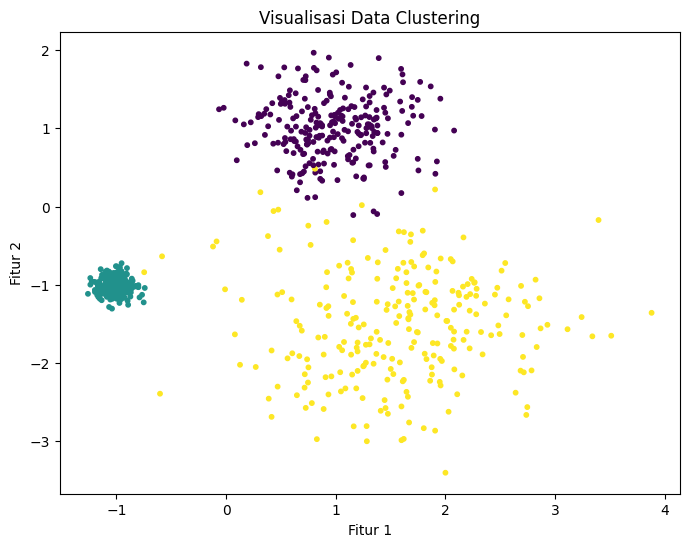

Jumlah data: 750
Jumlah fitur: 2


In [10]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs

# Membuat data sintetis
centers = [[1, 1], [-1, -1], [1.5, -1.5]]

X, labels_true = make_blobs(
    n_samples=750,
    centers=centers,
    cluster_std=[0.4, 0.1, 0.75],
    random_state=0
)

# Membuat fungsi visualisasi
def plot(X, labels=None, probabilities=None, ground_truth=False,
         param=None, ax=None):

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))

    if labels is None:
        labels = labels_true

    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=10)
    ax.set_title("Visualisasi Data Clustering")
    ax.set_xlabel("Fitur 1")
    ax.set_ylabel("Fitur 2")

    return ax

# Menampilkan visualisasi data
plot(X, labels=labels_true, ground_truth=True)
plt.show()

print("Jumlah data:", X.shape[0])
print("Jumlah fitur:", X.shape[1])

Langkah 1 - Eksperimen Hyperparameter min_cluster_size

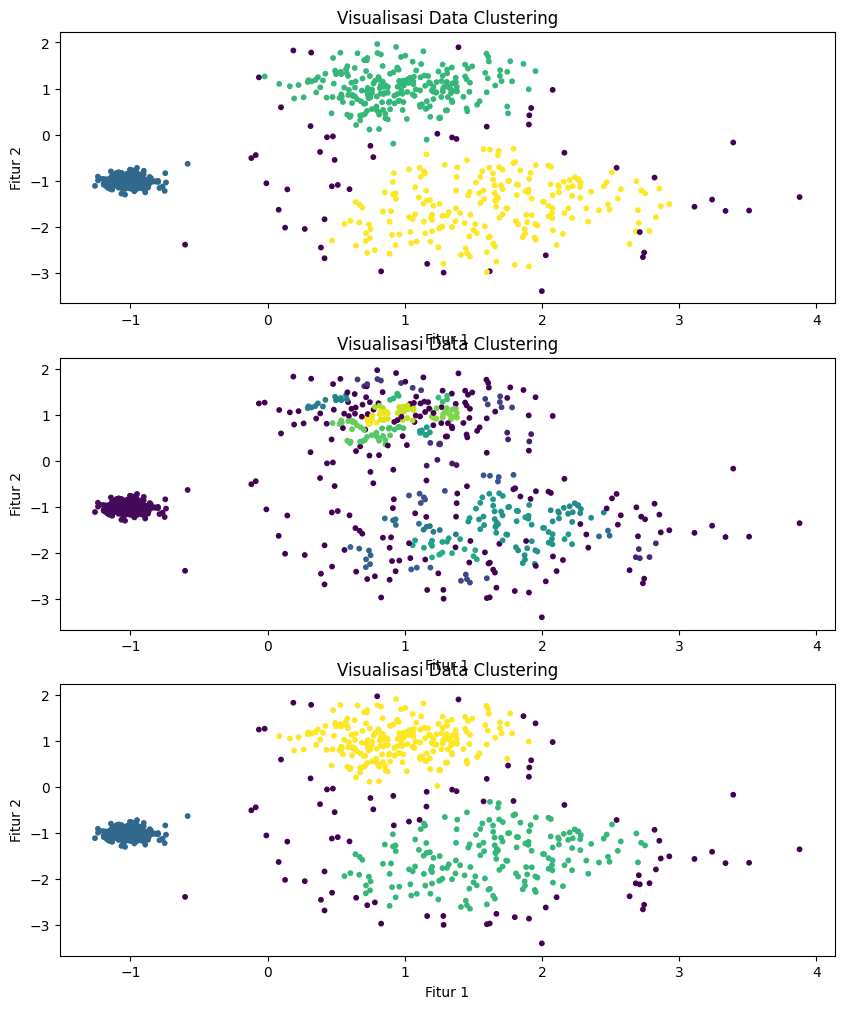

In [11]:
#Ubah nilai min_cluster_size.

PARAM = ({"min_cluster_size": 5}, {"min_cluster_size": 3}, {"min_cluster_size": 25})
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

Langkah 8: Eksperimen Hyperparameter min_samples

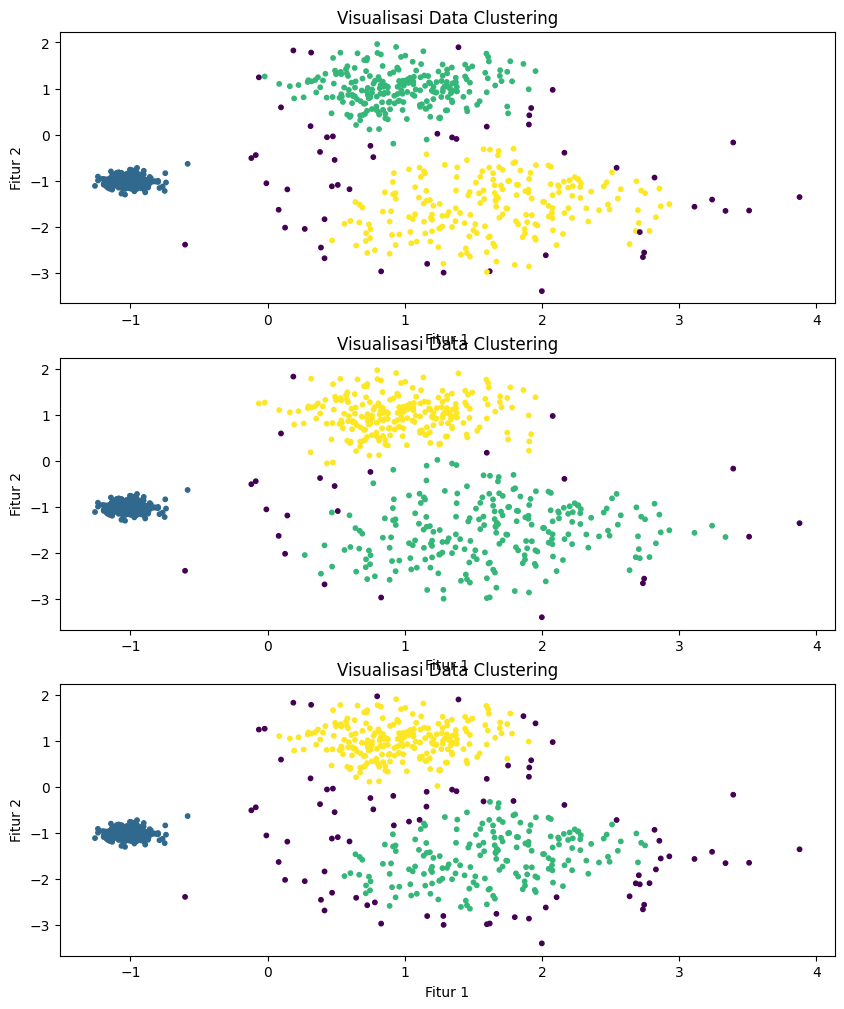

In [12]:
#Ubah nilai min_samples

PARAM = (
    {"min_cluster_size": 20, "min_samples": 5},
    {"min_cluster_size": 20, "min_samples": 3},
    {"min_cluster_size": 20, "min_samples": 25},
)
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

Langkah 9 - DBSCAN Clustering dari Pohon HDBSCAN

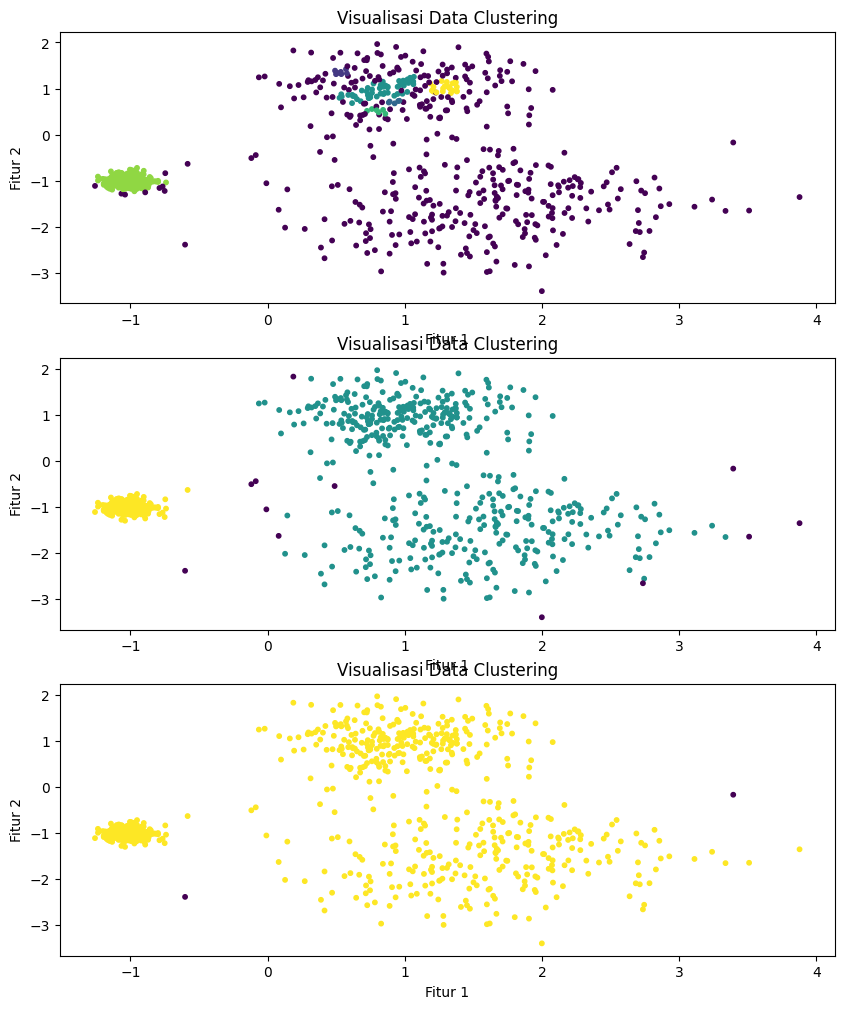

In [13]:
#Gunakan parameter cut_distance

PARAM = (
    {"cut_distance": 0.1},
    {"cut_distance": 0.5},
    {"cut_distance": 1.0},
)
hdb = hdbscan.HDBSCAN().fit(X)
fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    labels = hdb.dbscan_clustering(**param)
    plot(X, labels, hdb.probabilities_, param, ax=axes[i])

Langkah 10 -  Evaluasi dengan Silhouette Score

In [14]:
from sklearn.metrics import silhouette_score

# Menghitung Silhouette Score untuk hasil clustering HDBSCAN
sil_score = silhouette_score(X, hdb.labels_)
print(f"Silhouette Score: {sil_score}")

Silhouette Score: 0.6451356578011034


Langkah 11 - Evaluasi dengan Davies-Bouldin Index

In [15]:
from sklearn.metrics import davies_bouldin_score

# Menghitung Davies-Bouldin Index untuk hasil clustering HDBSCAN
dbi_score = davies_bouldin_score(X, hdb.labels_)
print(f"Davies-Bouldin Index: {dbi_score}")

Davies-Bouldin Index: 2.1284499880816123


Langkah 12 - Visualisasi Hasil Evaluasi

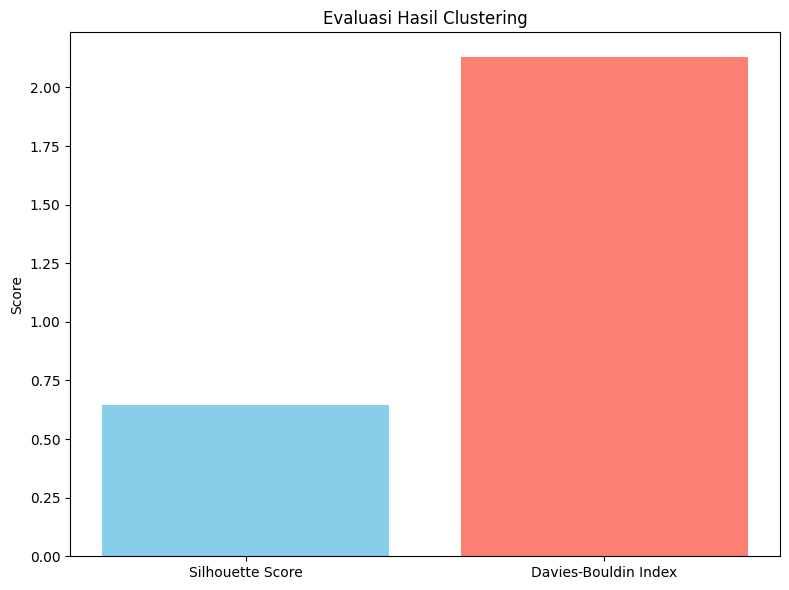

In [16]:
# Misalnya kita ingin membandingkan DBI dan Silhouette Score untuk beberapa eksperimen
scores = {
    "Silhouette Score": sil_score,
    "Davies-Bouldin Index": dbi_score
}

# Plot hasil evaluasi
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'])
ax.set_title("Evaluasi Hasil Clustering")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()